# Data Exploration - SegTHOR

Analysis suggestions: 

- Do some scans look brighter/darker because of acquisition differences?
- Are there artifacts, cropped anatomy, noisy labels, or missing structures?
- For medical imaging, don’t only visualize pretty examples. Visualize boring and bad cases too.

Explore The Labels
- How many classes are there?
- How often does each class appear?
- Are some classes tiny compared with background?
- Are annotations contiguous or fragmented?
- Do masks have holes, isolated islands, or suspicious boundaries?
- Does the same anatomy appear at similar locations across patients?
- Are labels balanced across train/validation?
- A good medical segmentation EDA usually includes class volumes, foreground ratios, slice-wise label presence, example overlays, and maybe connected-component statistics.

## Image Size, Spacing, Orientation, Type, and Intensity Range 

In [ ]:
# load .nii.gz of patient and corresponding ground truth file 
import nibabel as nib 

files_root = 'data/segthor_part1/train/'

# Load all training patients and their corresponding ground truth files
training_patients = [2,3,4,5,6,7,8,9,10,12,13,14,16,18,20]
patients = {}
for i in training_patients:
    patients[i] = {
        'image': nib.load(files_root + f'/Patient_{i:02d}/Patient_{i:02d}.nii.gz'),
        'ground_truth': nib.load(files_root + f'/Patient_{i:02d}/GT.nii.gz')
    }

# Check shape of loaded 3d volumes 
print("Patient 02 shape:", patients[2]['image'].shape)
print("Patient 02 GT shape:", patients[2]['ground_truth'].shape)

# Assert all patients have the same shape for image and ground truth
for i in patients:
    assert patients[i]['image'].shape == patients[i]['ground_truth'].shape, f"Patient {i} image and ground truth shapes do not match."
    
# Average shape of all patients
average_shape = tuple(sum(patients[i]['image'].shape[j] for i in patients) // len(patients) for j in range(3))
print("Average shape of all patients:", average_shape)
print("--------------------------------------------------------------------------")
print("Conclusion: Differs in number of slices (z-axis) but same resolutiion in x and y axes.")
print("--------------------------------------------------------------------------")

Patient 02 shape: (512, 512, 246)
Patient 02 GT shape: (512, 512, 246)
Average shape of all patients: (512, 512, 187)
--------------------------------------------------------------------------
Conclusion: Differs in number of slices (z-axis) but same resolutiion in x and y axes.
--------------------------------------------------------------------------


In [2]:
# Voxel sizes: 3D Voxel size in mm 
print("Patient 02 image zooms:", patients[2]['image'].header.get_zooms())
print("patient 02 GT zooms:", patients[2]['ground_truth'].header.get_zooms())

# Average voxel size of all patients
average_voxel_size = tuple(sum(patients[i]['image'].header.get_zooms()[j] for i in patients) / len(patients) for j in range(3))
print("Average voxel size of all patients:", average_voxel_size)

print("--------------------------------------------------------------------------")
print("Conclusion: Differs in voxels size in all axes (x, y, z).")
print("--------------------------------------------------------------------------")

Patient 02 image zooms: (np.float32(0.976562), np.float32(0.976562), np.float32(2.5))
patient 02 GT zooms: (np.float32(0.976562), np.float32(0.976562), np.float32(2.5))
Average voxel size of all patients: (np.float32(1.0026039), np.float32(1.0026039), np.float32(2.3333333))
--------------------------------------------------------------------------
Conclusion: Differs in voxels size in all axes (x, y, z).
--------------------------------------------------------------------------


In [3]:
# Orientation: Check orientation of all patients
orientation_patient_2 = nib.aff2axcodes(patients[2]['image'].affine)
print(f"Patient 2 image orientation:", orientation_patient_2)

# Check if any orientation differs from patient 2
differs = False
for i in patients:
    orientation = nib.aff2axcodes(patients[i]['image'].affine)
    if orientation != orientation_patient_2:
        print(f"Patient {i} image orientation differs from Patient 2:", orientation)
        differs = True
        
if not differs:
    print("---------------------------------------------------------------------------")
    print("Conclusion: All patients have the same image orientation.")
    print("---------------------------------------------------------------------------")
else: 
    print("---------------------------------------------------------------------------")
    print("Conclusion: At least one patient has a different image orientation.")
    print("---------------------------------------------------------------------------")

Patient 2 image orientation: ('L', 'P', 'S')
---------------------------------------------------------------------------
Conclusion: All patients have the same image orientation.
---------------------------------------------------------------------------


In [4]:
# Check image type (grayscale/rgb/etc.) of all patients

# Patient 2 image data type
patient_2_image_dtype = patients[2]['image'].get_data_dtype()
patient_2_gt_dtype = patients[2]['ground_truth'].get_data_dtype()
print(f"Patient 2 image data type:", patient_2_image_dtype)
print(f"Patient 2 GT data type:", patient_2_gt_dtype)

# Check if any image data type differs from patient 2
differs_dtype = False
for i in patients:
    image_dtype = patients[i]['image'].get_data_dtype()
    gt_dtype = patients[i]['ground_truth'].get_data_dtype()
    if image_dtype != patient_2_image_dtype:
        print(f"Patient {i} image data type differs from Patient 2:", image_dtype)
        differs_dtype = True
    if gt_dtype != patient_2_gt_dtype:
        print(f"Patient {i} GT data type differs from Patient 2:", gt_dtype)
        differs_dtype = True

if not differs_dtype:
    print("---------------------------------------------------------------------------")
    print("Conclusion: All patients have the same image and ground truth data type.")
    print("---------------------------------------------------------------------------")
else:
    print("---------------------------------------------------------------------------")
    print("Conclusion: At least one patient has a different image or ground truth data type.")
    print("---------------------------------------------------------------------------")

Patient 2 image data type: int32
Patient 2 GT data type: uint8
Patient 5 image data type differs from Patient 2: int16
Patient 13 image data type differs from Patient 2: int16
---------------------------------------------------------------------------
Conclusion: At least one patient has a different image or ground truth data type.
---------------------------------------------------------------------------


In [5]:
# Intensity range: Check intensity range of all patients

# Patient 2 image intensity range
image_data_2 = patients[2]['image'].get_fdata()
gt_data_2 = patients[2]['ground_truth'].get_fdata()
print(f"Patient 2 image intensity range: {image_data_2.min()} - {image_data_2.max()}")
print(f"Patient 2 GT intensity range: {gt_data_2.min()} - {gt_data_2.max()}")

# Average intensity range for patients and GT (separately)
avg_img_min = sum(patients[i]['image'].get_fdata().min() for i in patients) / len(patients)
avg_img_max = sum(patients[i]['image'].get_fdata().max() for i in patients) / len(patients)
avg_gt_min = sum(patients[i]['ground_truth'].get_fdata().min() for i in patients) / len(patients)
avg_gt_max = sum(patients[i]['ground_truth'].get_fdata().max() for i in patients) / len(patients)
print(f"Average image intensity range across all patients: {avg_img_min} - {avg_img_max}")
print(f"Average GT intensity range across all patients: {avg_gt_min} - {avg_gt_max}")

print("---------------------------------------------------------------------------")
print("Conclusion: Intensity ranges differ across patients for images but not for ground truths")
print("---------------------------------------------------------------------------")

Patient 2 image intensity range: -1000.0 - 26613.0
Patient 2 GT intensity range: 0.0 - 3.0
Average image intensity range across all patients: -1000.0 - 7526.866666666667
Average GT intensity range across all patients: 0.0 - 3.0
---------------------------------------------------------------------------
Conclusion: Intensity ranges differ across patients for images but not for ground truths
---------------------------------------------------------------------------


## Image Classes/Labels and presence per patient

In [6]:
# Find unique classes in ground truth files across all patients
unique_classes = set()
for i in patients:
    gt_data = patients[i]['ground_truth'].get_fdata()
    unique_classes.update(set(gt_data.flatten()))

print("Unique classes in ground truth files across all patients:", unique_classes)

Unique classes in ground truth files across all patients: {np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)}


In [8]:
# Map classes to their corresponding labels based on the provided information
# SegTHOR has: Heart, Aorta, Trachea, Oesophagus, And Background (but we only have 4 classes in the ground truth files, so we will map them as follows):
#0 = background
#1 = esophagus
#2 = heart
#3 = trachea
#4 = aorta (not present in ground truth files)

label_mapping = {
    0: 'background',
    1: 'esophagus_or_aorta',  # Both esophagus and aorta are represented by the same value in the ground truth files
    2: 'heart',
    3: 'trachea',
    4: 'aorta'  # Not present in ground truth files
}

# Check if all classes are present in each patient's ground truth file and print if there's any unknown or missing class
missing_classes_reported = False
unknown_classes_reported = False
for i in patients:
    gt_data = patients[i]['ground_truth'].get_fdata()
    patient_classes = set(gt_data.flatten())
    
    # Check for unknown classes
    unknown_classes = patient_classes - set(label_mapping.keys())
    if unknown_classes:
        print(f"Patient {i} has unknown classes in ground truth:", unknown_classes)
    
    # Check for missing classes
    missing_classes = set(label_mapping.keys()) - patient_classes
    if missing_classes:
        print(f"Patient {i} is missing classes in ground truth:", missing_classes)
        missing_classes_reported = True

    if unknown_classes:
        unknown_classes_reported = True

if not missing_classes_reported and not unknown_classes_reported:
    print("---------------------------------------------------------------------------")
    print("All patients have the expected classes in their ground truth files.")
    print("---------------------------------------------------------------------------")
else:
    print("---------------------------------------------------------------------------")
    print("Some patients have unknown or missing classes in their ground truth files.")
    print("---------------------------------------------------------------------------")

Patient 2 is missing classes in ground truth: {4}
Patient 3 is missing classes in ground truth: {4}
Patient 4 is missing classes in ground truth: {4}
Patient 5 is missing classes in ground truth: {4}
Patient 6 is missing classes in ground truth: {4}
Patient 7 is missing classes in ground truth: {4}
Patient 8 is missing classes in ground truth: {4}
Patient 9 is missing classes in ground truth: {4}
Patient 10 is missing classes in ground truth: {4}
Patient 12 is missing classes in ground truth: {4}
Patient 13 is missing classes in ground truth: {4}
Patient 14 is missing classes in ground truth: {4}
Patient 16 is missing classes in ground truth: {4}
Patient 18 is missing classes in ground truth: {4}
Patient 20 is missing classes in ground truth: {4}
---------------------------------------------------------------------------
Some patients have unknown or missing classes in their ground truth files.
---------------------------------------------------------------------------


## Image Slice Exploration (Per patient)

In [16]:
import PIL.Image as Image
import matplotlib.pyplot as plt

slice_label_mapping = {
    0: 'background',
    63: 'esophagus_or_aorta',  # Both esophagus and aorta are represented by the same value in the ground truth files
    126: 'heart',
    189: 'trachea',
    252: 'aorta'  # Not present in ground truth files
}
def explore_image_slices(patient_number, gt=True):
    root_dir_gt_slices = 'data/SEGTHOR/train/gt'
    root_dir_img_slices = 'data/SEGTHOR/train/img'
    patient_slices_count = patients[patient_number]['ground_truth'if gt else 'image'].shape[2]
    patient_slices = [Image.open(f"{root_dir_gt_slices if gt else root_dir_img_slices}/Patient_{patient_number:02d}_{i:04d}.png") for i in range(patient_slices_count)]
    print(len(patient_slices), "slices loaded for Patient", patient_number, "from", "ground truth" if gt else "image")

    # Class-presence HEATMAP plotting:
    patient_slice_classes = [set(slice.get_flattened_data()) for slice in patient_slices]
    class_presence = [
        [cls if cls in slice_classes else 0 for slice_classes in patient_slice_classes]
        for cls in slice_label_mapping
    ]
    # HEATMAP: class-presence heatmap: x-axis slice index, y-axis class.
    plt.figure(figsize=(10, 6))
    plt.imshow(class_presence, cmap='viridis', aspect='auto')
    cbar = plt.colorbar(ticks=list(slice_label_mapping.keys()), label='Classes')
    cbar.set_ticklabels(list(slice_label_mapping.values()))
    plt.title(f'Class Presence Heatmap for Patient {patient_number} {"Ground Truth" if gt else "Image"} Slices')
    plt.xlabel('Slice Number')
    plt.yticks([])
    plt.show()

### Image Slice Exploration (Patient 02)

246 slices loaded for Patient 2 from ground truth


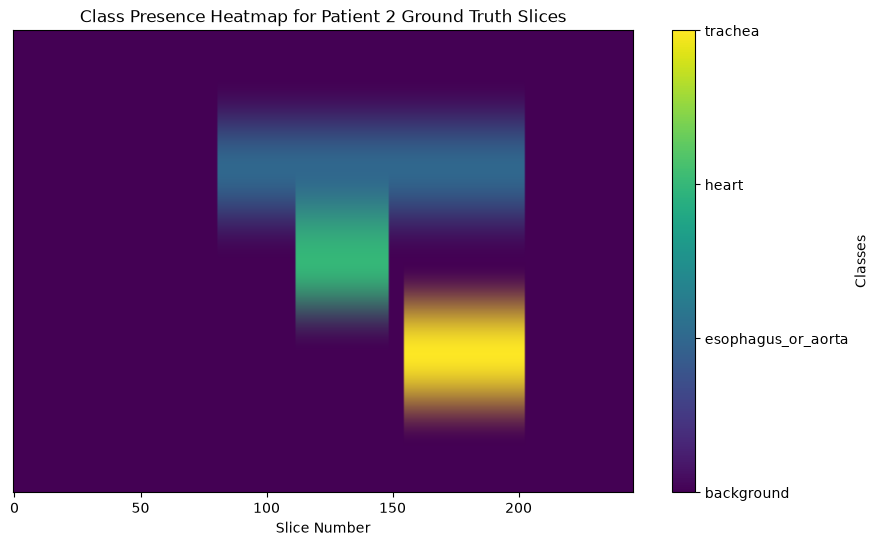

In [17]:
explore_image_slices(2, gt=True)

### Image Slice Exploration (Patient 10)

163 slices loaded for Patient 10 from ground truth


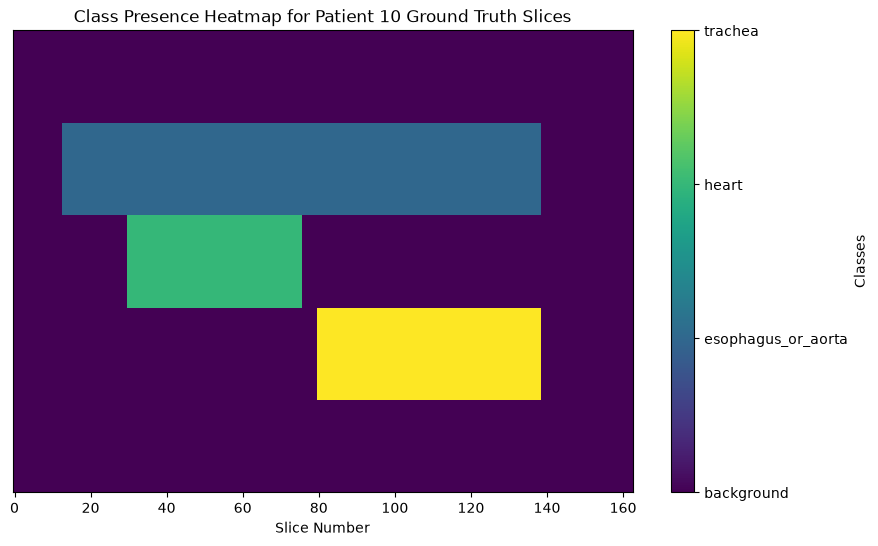

In [18]:
explore_image_slices(10, gt=True)

### Image Slice Exploration (Patient 07)

179 slices loaded for Patient 7 from ground truth


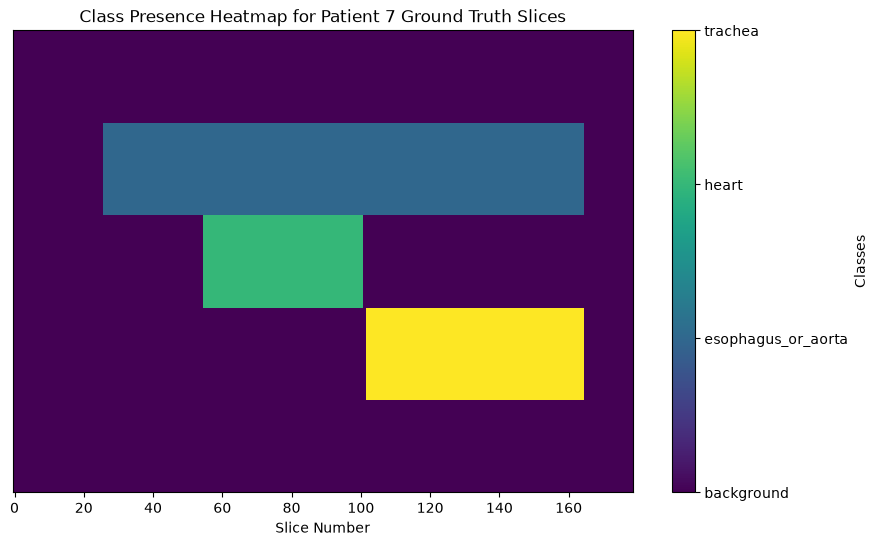

In [19]:
explore_image_slices(7, gt=True)

### Image Slice Exploration (Patient 20)

206 slices loaded for Patient 20 from ground truth


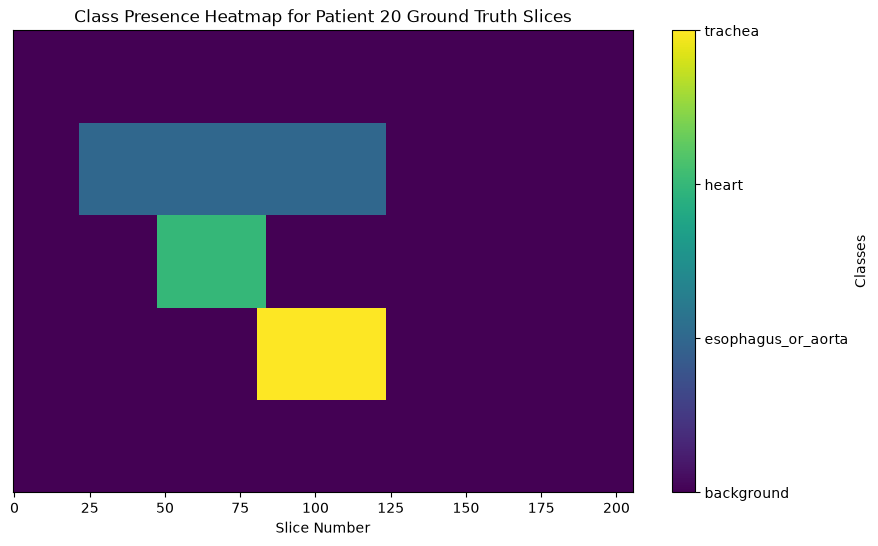

In [20]:
explore_image_slices(20, gt=True)

## Image Slice Exploration (Patient Averages)

In [21]:
# Load all training data from 2D slice root (gt only)
import PIL.Image as Image
import os

train_gt_root = 'data/SEGTHOR/train/gt'

# count total number of slices from dir
max_patients = 20
max_slices_per_patient = 300
all_gt_slices = [Image.open(f"{train_gt_root}/Patient_{i:02d}_{j:04d}.png") for i in range(1, max_patients + 1) for j in range(0, max_slices_per_patient) if os.path.exists(f"{train_gt_root}/Patient_{i:02d}_{j:04d}.png")]

In [27]:
import numpy as np 

# Total patients loaded: find unique patient numbers from the loaded slices
loaded_patient_numbers = set(int(slice_img.filename.split('/')[-1].split('_')[1]) for slice_img in all_gt_slices)
print("Total number of patients loaded:", len(loaded_patient_numbers))

# Total number of slices across all patients
print("Total number of ground truth slices loaded:", len(all_gt_slices))

# Avg slices per patient 
avg_slices_per_patient = len(all_gt_slices) / len(loaded_patient_numbers)
print(f"Average number of slices per patient:", f"{avg_slices_per_patient:.2f}")

# Percentage of background-only slices 
background_only_slices = sum(1 for slice_img in all_gt_slices if np.all(np.array(slice_img) == 0))
avg_background_only_slices = (background_only_slices / len(all_gt_slices)) * 100
print(f"Percentage of background-only slices overall:", f"{avg_background_only_slices:.2f}")

# Percentage of slices containing each class (excluding background) overall
class_slice_counts = {cls: 0 for cls in slice_label_mapping.keys() if cls != 0}
for slice_img in all_gt_slices:
    slice_data = np.array(slice_img)
    available_classes = set(slice_data.flatten())
    for cls in class_slice_counts.keys():
        if cls in available_classes:
            class_slice_counts[cls] += 1
# 2 decimal places 
class_slice_percentages = {slice_label_mapping[cls]: round((count / len(all_gt_slices)) * 100, 2) for cls, count in class_slice_counts.items()}
print("Percentage of slices containing each class (excluding background) overall:", class_slice_percentages)

# Min/Median/Max counts of slices containing each class (excluding background) per patient
class_slice_counts_per_patient = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    patient_slices = [slice_img for slice_img in all_gt_slices if int(slice_img.filename.split('/')[-1].split('_')[1]) == i]
    for cls in class_slice_counts_per_patient.keys():
        count = sum(1 for slice_img in patient_slices if cls in set(np.array(slice_img).flatten()))
        class_slice_counts_per_patient[cls].append(count)
class_slice_stats = {slice_label_mapping[cls]: {'min': min(counts), 'median': np.median(counts), 'max': max(counts)} for cls, counts in class_slice_counts_per_patient.items()}
print("Min/Median/Max counts of slices containing each class (excluding background) per patient:", class_slice_stats)
               
# Percentage of slices containing multiple classes (excluding background) overall
multi_class_slices = sum(1 for slice_img in all_gt_slices if len(set(np.array(slice_img).flatten()) - {0}) > 1)
avg_multi_class_slices = (multi_class_slices / len(all_gt_slices)) * 100
print(f"Percentage of slices containing multiple classes (excluding background) overall:", f"{avg_multi_class_slices:.2f}")

# Average voxel/foreground ratio per class per patient (excluding background)
voxel_foreground_ratio = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    for j in range(0, max_slices_per_patient):
        slice_path = f"{train_gt_root}/Patient_{i:02d}_{j:04d}.png"
        if os.path.exists(slice_path):
            slice_img = Image.open(slice_path)
            slice_data = np.array(slice_img)
            total_voxels = slice_data.size
            for cls in voxel_foreground_ratio.keys():
                if cls in set(slice_data.flatten()):
                    foreground_voxels = np.sum(slice_data == cls)
                    voxel_foreground_ratio[cls].append(foreground_voxels / total_voxels)
print("Average voxel/foreground ratio per class per patient (excluding background):", {slice_label_mapping[cls]: round(np.mean(ratios),5) for cls, ratios in voxel_foreground_ratio.items()})

# Average voxel volume (mm3) per class per patient (excluding background)
voxel_volumes = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    for j in range(0, max_slices_per_patient):
        slice_path = f"{train_gt_root}/Patient_{i:02d}_{j:04d}.png"
        if os.path.exists(slice_path):
            slice_img = Image.open(slice_path)
            slice_data = np.array(slice_img)
            voxel_size = patients[i]['image'].header.get_zooms()  # Get voxel size for the patient
            voxel_volume = np.prod(voxel_size)  # Calculate voxel volume in mm^3
            for cls in voxel_volumes.keys():
                if cls in set(slice_data.flatten()):
                    foreground_voxels = np.sum(slice_data == cls)
                    voxel_volumes[cls].append(foreground_voxels * voxel_volume)
print("Average voxel volume (mm3) per class per patient (excluding background):", {slice_label_mapping[cls]: round(np.mean(volumes), 2) for cls, volumes in voxel_volumes.items()})

# Average z-start and z-end positions of each class per patient (excluding background) 
for cls in slice_label_mapping.keys():
    z_starts = []
    z_ends = []
    for i in range(1, max_patients + 1):
        present_slices = []
        for j in range(0, max_slices_per_patient):
            slice_path = f"{train_gt_root}/Patient_{i:02d}_{j:04d}.png"
            if os.path.exists(slice_path):
                slice_img = Image.open(slice_path)
                slice_data = np.array(slice_img)
                if cls in set(slice_data.flatten()):
                    present_slices.append(j)
        if present_slices:
            z_starts.append(min(present_slices))
            z_ends.append(max(present_slices))
    mean_z_start = np.mean(z_starts) if z_starts else None
    mean_z_end = np.mean(z_ends) if z_ends else None
    mean_slices_present = mean_z_end - mean_z_start + 1 if mean_z_start is not None and mean_z_end is not None else None
    print(f"Class {slice_label_mapping[cls]}: Mean Z-Start: {round(mean_z_start, 2) if mean_z_start is not None else None}, Mean Z-End: {round(mean_z_end, 2) if mean_z_end is not None else None}, Min Z-Range: {round(min(z_starts),2) if z_starts else None}, Max Z-Range: {round(max(z_ends),2) if z_ends else None}, Mean Number of Slices Containing Class: {round(mean_slices_present, 2) if mean_slices_present is not None else None}")

Total number of patients loaded: 15
Total number of ground truth slices loaded: 2817
Average number of slices per patient: 187.80
Percentage of background-only slices overall: 36.42
Percentage of slices containing each class (excluding background) overall: {'esophagus_or_aorta': 63.51, 'heart': 22.51, 'trachea': 27.76, 'aorta': 0.0}
Min/Median/Max counts of slices containing each class (excluding background) per patient: {'esophagus_or_aorta': {'min': 0, 'median': np.float64(109.0), 'max': 142}, 'heart': {'min': 0, 'median': np.float64(38.5), 'max': 62}, 'trachea': {'min': 0, 'median': np.float64(48.5), 'max': 65}, 'aorta': {'min': 0, 'median': np.float64(0.0), 'max': 0}}
Percentage of slices containing multiple classes (excluding background) overall: 50.02
Average voxel/foreground ratio per class per patient (excluding background): {'esophagus_or_aorta': np.float64(0.00369), 'heart': np.float64(0.03484), 'trachea': np.float64(0.00123), 'aorta': np.float64(nan)}
Average voxel volume (m

## Validation Data explore

### Part 1 (Image-specific checks)

In [30]:
import nibabel as nib 

files_root_val = 'data/segthor_part1/train/'

validation_patients = [1,11,15,17,19]
val_patients = {}
for i in validation_patients:
    val_patients[i] = {
        'image': nib.load(files_root_val + f'/Patient_{i:02d}/Patient_{i:02d}.nii.gz'),
        'ground_truth': nib.load(files_root_val + f'/Patient_{i:02d}/GT.nii.gz')
    }

# Check shape of loaded 3d volumes 
print("Patient 01 image shape:", val_patients[1]['image'].shape)
print("Patient 01 GT shape:", val_patients[1]['ground_truth'].shape)

# Assert all patients have the same shape for image and ground truth
for i in val_patients:
    assert val_patients[i]['image'].shape == val_patients[i]['ground_truth'].shape, f"Patient {i} image and ground truth shapes do not match."
    
# Average shape of all patients
average_shape = tuple(sum(val_patients[i]['image'].shape[j] for i in val_patients) // len(val_patients) for j in range(3))
print("Average shape of all patients:", average_shape)
print("--------------------------------------------------------------------------")
print("Conclusion: Differs in number of slices (z-axis) but same resolutiion in x and y axes.")
print("--------------------------------------------------------------------------")

Patient 01 image shape: (512, 512, 229)
Patient 01 GT shape: (512, 512, 229)
Average shape of all patients: (512, 512, 183)
--------------------------------------------------------------------------
Conclusion: Differs in number of slices (z-axis) but same resolutiion in x and y axes.
--------------------------------------------------------------------------


In [31]:
# Voxel sizes: 3D Voxel size in mm 
print("Patient 01 image zooms:", val_patients[1]['image'].header.get_zooms())
print("Patient 01 GT zooms:", val_patients[1]['ground_truth'].header.get_zooms())

# Average voxel size of all patients
average_voxel_size = tuple(sum(val_patients[i]['image'].header.get_zooms()[j] for i in val_patients) / len(val_patients) for j in range(3))
print("Average voxel size of all patients:", average_voxel_size)

print("--------------------------------------------------------------------------")
print("Conclusion: Differs in voxels size in all axes (x, y, z).")
print("--------------------------------------------------------------------------")

Patient 01 image zooms: (np.float32(0.9765625), np.float32(0.9765625), np.float32(2.0))
Patient 01 GT zooms: (np.float32(0.9765625), np.float32(0.9765625), np.float32(2.0))
Average voxel size of all patients: (np.float32(1.0191404), np.float32(1.0191404), np.float32(2.4))
--------------------------------------------------------------------------
Conclusion: Differs in voxels size in all axes (x, y, z).
--------------------------------------------------------------------------


In [32]:
# Orientation: Check orientation of all patients
orientation_patient_1 = nib.aff2axcodes(val_patients[1]['image'].affine)
print(f"Patient 1 image orientation:", orientation_patient_1)

# Check if any orientation differs from patient 1
differs = False
for i in val_patients:
    orientation = nib.aff2axcodes(val_patients[i]['image'].affine)
    if orientation != orientation_patient_1:
        print(f"Patient {i} image orientation differs from Patient 1:", orientation)
        differs = True
        
if not differs:
    print("---------------------------------------------------------------------------")
    print("Conclusion: All patients have the same image orientation.")
    print("---------------------------------------------------------------------------")
else: 
    print("---------------------------------------------------------------------------")
    print("Conclusion: At least one patient has a different image orientation.")
    print("---------------------------------------------------------------------------")

Patient 1 image orientation: ('L', 'P', 'S')
---------------------------------------------------------------------------
Conclusion: All patients have the same image orientation.
---------------------------------------------------------------------------


In [33]:
# Check image type (grayscale/rgb/etc.) of all patients

# Patient 1 image data type
patient_1_image_dtype = val_patients[1]['image'].get_data_dtype()
patient_1_gt_dtype = val_patients[1]['ground_truth'].get_data_dtype()
print(f"Patient 1 image data type:", patient_1_image_dtype)
print(f"Patient 1 GT data type:", patient_1_gt_dtype)

# Check if any image data type differs from patient 1
differs_dtype = False
for i in val_patients:
    image_dtype = val_patients[i]['image'].get_data_dtype()
    gt_dtype = val_patients[i]['ground_truth'].get_data_dtype()
    if image_dtype != patient_1_image_dtype:
        print(f"Patient {i} image data type differs from Patient 1:", image_dtype)
        differs_dtype = True
    if gt_dtype != patient_1_gt_dtype:
        print(f"Patient {i} GT data type differs from Patient 1:", gt_dtype)
        differs_dtype = True

if not differs_dtype:
    print("---------------------------------------------------------------------------")
    print("Conclusion: All patients have the same image and ground truth data type.")
    print("---------------------------------------------------------------------------")
else:
    print("---------------------------------------------------------------------------")
    print("Conclusion: At least one patient has a different image or ground truth data type.")
    print("---------------------------------------------------------------------------")

Patient 1 image data type: int16
Patient 1 GT data type: uint8
Patient 11 image data type differs from Patient 1: int32
Patient 15 image data type differs from Patient 1: int32
Patient 17 image data type differs from Patient 1: int32
Patient 19 image data type differs from Patient 1: int32
---------------------------------------------------------------------------
Conclusion: At least one patient has a different image or ground truth data type.
---------------------------------------------------------------------------


In [34]:
# Intensity range: Check intensity range of all patients

# Patient 1 image intensity range
image_data_1 = val_patients[1]['image'].get_fdata()
gt_data_1 = val_patients[1]['ground_truth'].get_fdata()
print(f"Patient 1 image intensity range: {image_data_1.min()} - {image_data_1.max()}")
print(f"Patient 1 GT intensity range: {gt_data_1.min()} - {gt_data_1.max()}")

# Average intensity range for patients and GT (separately)
avg_img_min = sum(val_patients[i]['image'].get_fdata().min() for i in val_patients) / len(val_patients)
avg_img_max = sum(val_patients[i]['image'].get_fdata().max() for i in val_patients) / len(val_patients)
avg_gt_min = sum(val_patients[i]['ground_truth'].get_fdata().min() for i in val_patients) / len(val_patients)
avg_gt_max = sum(val_patients[i]['ground_truth'].get_fdata().max() for i in val_patients) / len(val_patients)
print(f"Average image intensity range across all patients: {avg_img_min} - {avg_img_max}")
print(f"Average GT intensity range across all patients: {avg_gt_min} - {avg_gt_max}")

print("---------------------------------------------------------------------------")
print("Conclusion: Intensity ranges differ across patients for images but not for ground truths")
print("---------------------------------------------------------------------------")

Patient 1 image intensity range: -1000.0 - 3071.0
Patient 1 GT intensity range: 0.0 - 3.0
Average image intensity range across all patients: -1000.0 - 15204.8
Average GT intensity range across all patients: 0.0 - 3.0
---------------------------------------------------------------------------
Conclusion: Intensity ranges differ across patients for images but not for ground truths
---------------------------------------------------------------------------


### Part 2: Label presence and exploration 

In [35]:
# Find unique classes in ground truth files across all patients
unique_classes = set()
for i in val_patients:
    gt_data = val_patients[i]['ground_truth'].get_fdata()
    unique_classes.update(set(gt_data.flatten()))

print("Unique classes in ground truth files across all patients:", unique_classes)

Unique classes in ground truth files across all patients: {np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)}


In [36]:
# Map classes to their corresponding labels based on the provided information
# SegTHOR has: Heart, Aorta, Trachea, Oesophagus, And Background (but we only have 4 classes in the ground truth files, so we will map them as follows):
#0 = background
#1 = esophagus
#2 = heart
#3 = trachea
#4 = aorta (not present in ground truth files)

label_mapping = {
    0: 'background',
    1: 'esophagus_or_aorta',  # Both esophagus and aorta are represented by the same value in the ground truth files
    2: 'heart',
    3: 'trachea',
    4: 'aorta'  # Not present in ground truth files
}

# Check if all classes are present in each patient's ground truth file and print if there's any unknown or missing class
missing_classes_reported = False
unknown_classes_reported = False
for i in val_patients:
    gt_data = val_patients[i]['ground_truth'].get_fdata()
    patient_classes = set(gt_data.flatten())
    
    # Check for unknown classes
    unknown_classes = patient_classes - set(label_mapping.keys())
    if unknown_classes:
        print(f"Patient {i} has unknown classes in ground truth:", unknown_classes)
    
    # Check for missing classes
    missing_classes = set(label_mapping.keys()) - patient_classes
    if missing_classes:
        print(f"Patient {i} is missing classes in ground truth:", missing_classes)
        missing_classes_reported = True

    if unknown_classes:
        unknown_classes_reported = True

if not missing_classes_reported and not unknown_classes_reported:
    print("---------------------------------------------------------------------------")
    print("All patients have the expected classes in their ground truth files.")
    print("---------------------------------------------------------------------------")
else:
    print("---------------------------------------------------------------------------")
    print("Some patients have unknown or missing classes in their ground truth files.")
    print("---------------------------------------------------------------------------")

Patient 1 is missing classes in ground truth: {4}
Patient 11 is missing classes in ground truth: {4}
Patient 15 is missing classes in ground truth: {4}
Patient 17 is missing classes in ground truth: {4}
Patient 19 is missing classes in ground truth: {4}
---------------------------------------------------------------------------
Some patients have unknown or missing classes in their ground truth files.
---------------------------------------------------------------------------


### Part 3: Image slice exploration (per patient)

In [37]:
import PIL.Image as Image
import matplotlib.pyplot as plt

slice_label_mapping = {
    0: 'background',
    63: 'esophagus_or_aorta',  # Both esophagus and aorta are represented by the same value in the ground truth files
    126: 'heart',
    189: 'trachea',
    252: 'aorta'  # Not present in ground truth files
}
def explore_image_slices(patient_number, gt=True):
    root_dir_gt_slices = 'data/SEGTHOR/val/gt'
    root_dir_img_slices = 'data/SEGTHOR/val/img'
    patient_slices_count = val_patients[patient_number]['ground_truth'if gt else 'image'].shape[2]
    patient_slices = [Image.open(f"{root_dir_gt_slices if gt else root_dir_img_slices}/Patient_{patient_number:02d}_{i:04d}.png") for i in range(patient_slices_count)]
    print(len(patient_slices), "slices loaded for Patient", patient_number, "from", "ground truth" if gt else "image")

    # Class-presence HEATMAP plotting:
    patient_slice_classes = [set(slice.get_flattened_data()) for slice in patient_slices]
    class_presence = [
        [cls if cls in slice_classes else 0 for slice_classes in patient_slice_classes]
        for cls in slice_label_mapping
    ]
    # HEATMAP: class-presence heatmap: x-axis slice index, y-axis class.
    plt.figure(figsize=(10, 6))
    plt.imshow(class_presence, cmap='viridis', aspect='auto')
    cbar = plt.colorbar(ticks=list(slice_label_mapping.keys()), label='Classes')
    cbar.set_ticklabels(list(slice_label_mapping.values()))
    plt.title(f'Class Presence Heatmap for Patient {patient_number} {"Ground Truth" if gt else "Image"} Slices')
    plt.xlabel('Slice Number')
    plt.yticks([])
    plt.show()

229 slices loaded for Patient 1 from ground truth


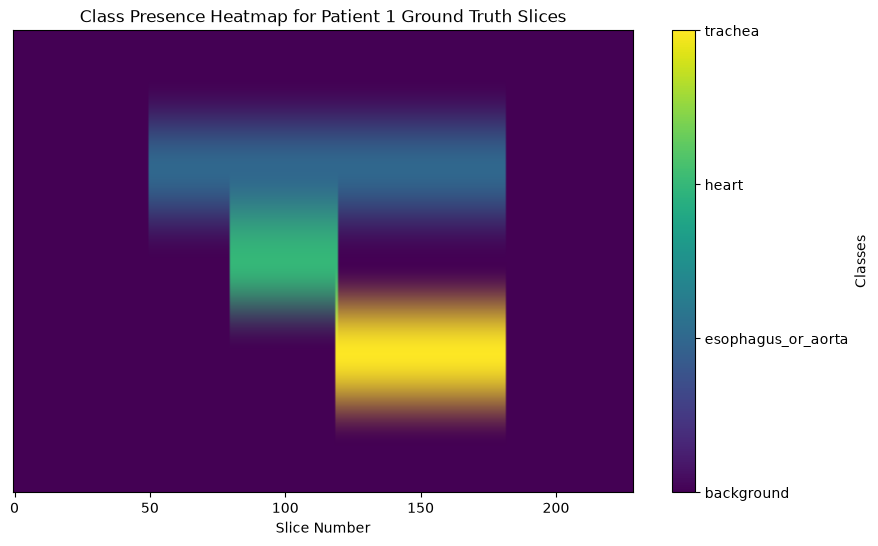

180 slices loaded for Patient 11 from ground truth


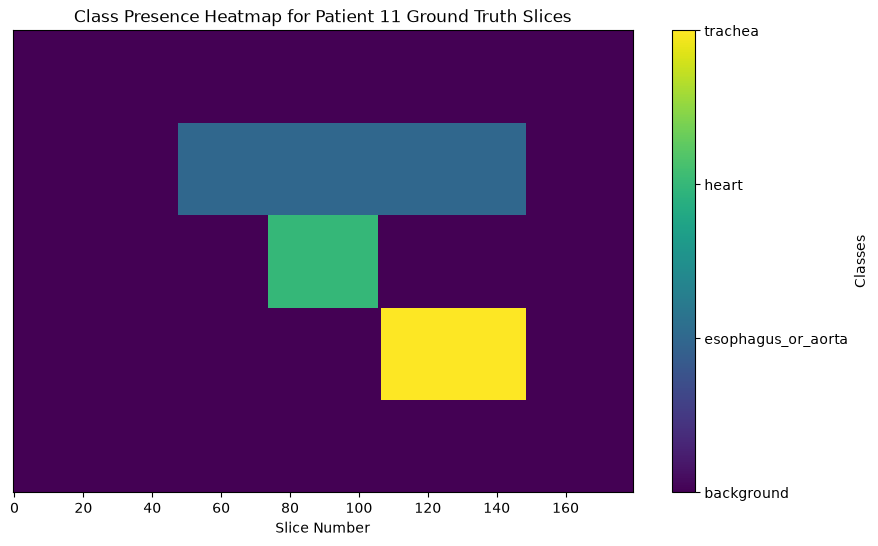

150 slices loaded for Patient 15 from ground truth


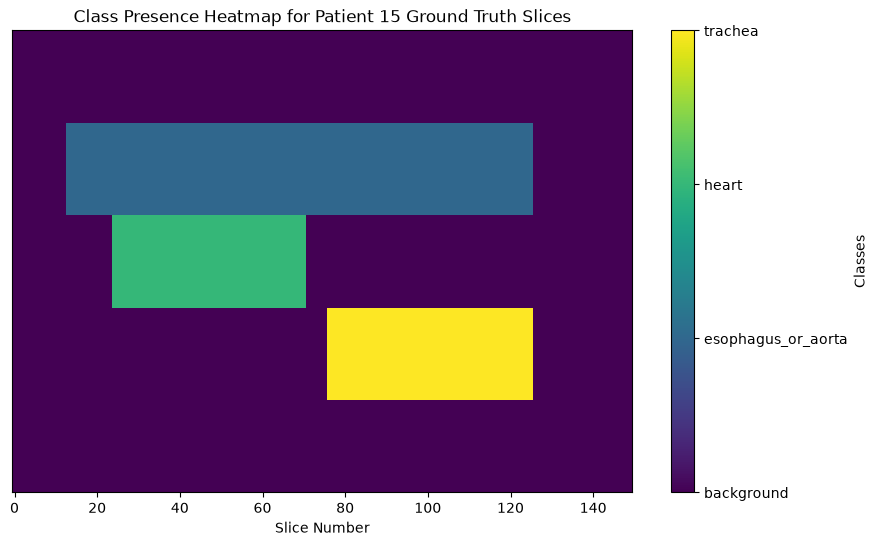

166 slices loaded for Patient 17 from ground truth


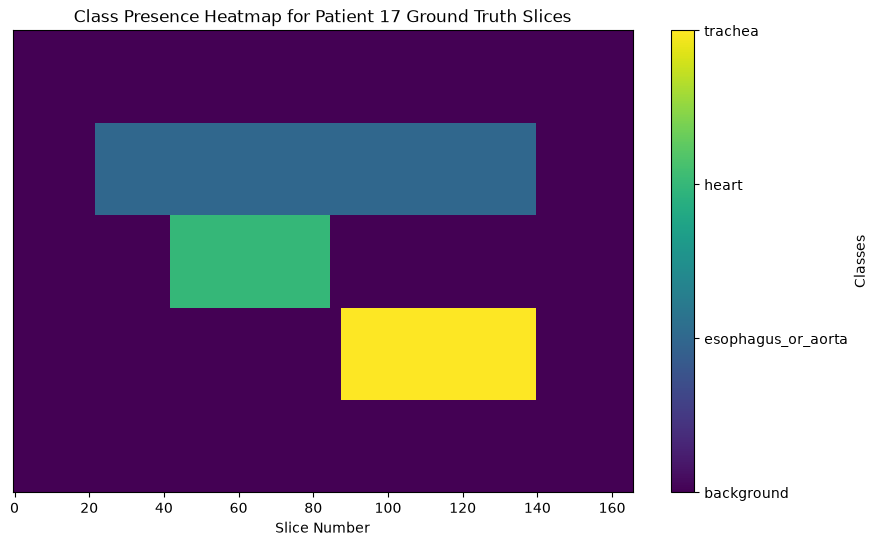

190 slices loaded for Patient 19 from ground truth


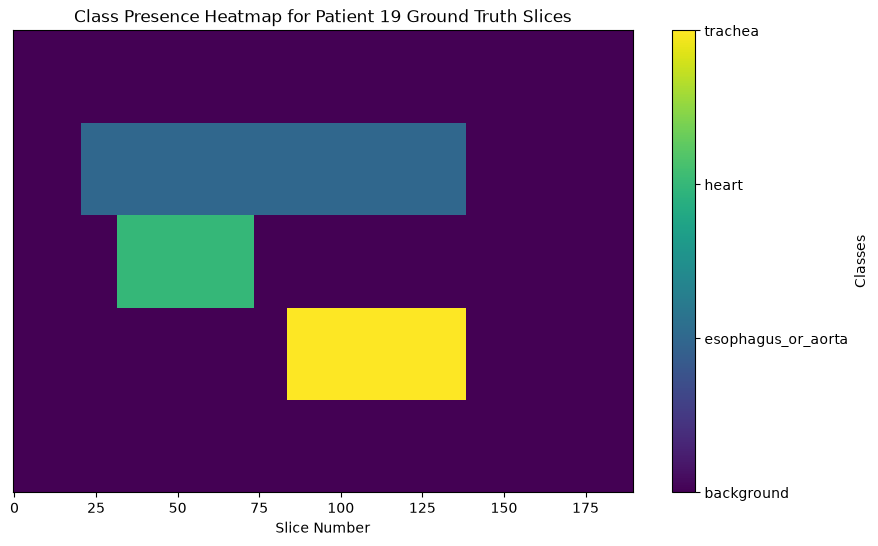

In [38]:
explore_image_slices(1, gt=True)
explore_image_slices(11, gt=True)
explore_image_slices(15, gt=True)
explore_image_slices(17, gt=True)
explore_image_slices(19, gt=True)

### Part 4: Image Slice Exploration (patient averages)

In [39]:
# Load all training data from 2D slice root (gt only)
import PIL.Image as Image
import os

val_gt_root = 'data/SEGTHOR/val/gt'

# count total number of slices from dir
max_patients = 20
max_slices_per_patient = 300
all_gt_slices = [Image.open(f"{val_gt_root}/Patient_{i:02d}_{j:04d}.png") for i in range(1, max_patients + 1) for j in range(0, max_slices_per_patient) if os.path.exists(f"{val_gt_root}/Patient_{i:02d}_{j:04d}.png")]

In [42]:
import numpy as np 

# Total patients loaded: find unique patient numbers from the loaded slices
loaded_patient_numbers = set(int(slice_img.filename.split('/')[-1].split('_')[1]) for slice_img in all_gt_slices)
print("Total number of patients loaded:", len(loaded_patient_numbers))

# Total number of slices across all patients
print("Total number of ground truth slices loaded:", len(all_gt_slices))

# Avg slices per patient 
avg_slices_per_patient = len(all_gt_slices) / len(loaded_patient_numbers)
print(f"Average number of slices per patient:", f"{avg_slices_per_patient:.2f}")

# Percentage of background-only slices 
background_only_slices = sum(1 for slice_img in all_gt_slices if np.all(np.array(slice_img) == 0))
avg_background_only_slices = (background_only_slices / len(all_gt_slices)) * 100
print(f"Percentage of background-only slices overall:", f"{avg_background_only_slices:.2f}")

# Percentage of slices containing each class (excluding background) overall
class_slice_counts = {cls: 0 for cls in slice_label_mapping.keys() if cls != 0}
for slice_img in all_gt_slices:
    slice_data = np.array(slice_img)
    available_classes = set(slice_data.flatten())
    for cls in class_slice_counts.keys():
        if cls in available_classes:
            class_slice_counts[cls] += 1
# 2 decimal places 
class_slice_percentages = {slice_label_mapping[cls]: round((count / len(all_gt_slices)) * 100, 2) for cls, count in class_slice_counts.items()}
print("Percentage of slices containing each class (excluding background) overall:", class_slice_percentages)

# Min/Median/Max counts of slices containing each class (excluding background) per patient
class_slice_counts_per_patient = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    patient_slices = [slice_img for slice_img in all_gt_slices if int(slice_img.filename.split('/')[-1].split('_')[1]) == i]
    for cls in class_slice_counts_per_patient.keys():
        count = sum(1 for slice_img in patient_slices if cls in set(np.array(slice_img).flatten()))
        class_slice_counts_per_patient[cls].append(count)
class_slice_stats = {slice_label_mapping[cls]: {'min': min(counts), 'median': np.median(counts), 'max': max(counts)} for cls, counts in class_slice_counts_per_patient.items()}
print("Min/Median/Max counts of slices containing each class (excluding background) per patient:", class_slice_stats)
               
# Percentage of slices containing multiple classes (excluding background) overall
multi_class_slices = sum(1 for slice_img in all_gt_slices if len(set(np.array(slice_img).flatten()) - {0}) > 1)
avg_multi_class_slices = (multi_class_slices / len(all_gt_slices)) * 100
print(f"Percentage of slices containing multiple classes (excluding background) overall:", f"{avg_multi_class_slices:.2f}")

# Average voxel/foreground ratio per class per patient (excluding background)
voxel_foreground_ratio = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    for j in range(0, max_slices_per_patient):
        slice_path = f"{val_gt_root}/Patient_{i:02d}_{j:04d}.png"
        if os.path.exists(slice_path):
            slice_img = Image.open(slice_path)
            slice_data = np.array(slice_img)
            total_voxels = slice_data.size
            for cls in voxel_foreground_ratio.keys():
                if cls in set(slice_data.flatten()):
                    foreground_voxels = np.sum(slice_data == cls)
                    voxel_foreground_ratio[cls].append(foreground_voxels / total_voxels)
print("Average voxel/foreground ratio per class per patient (excluding background):", {slice_label_mapping[cls]: round(np.mean(ratios),5) for cls, ratios in voxel_foreground_ratio.items()})

# Average voxel volume (mm3) per class per patient (excluding background)
voxel_volumes = {cls: [] for cls in slice_label_mapping.keys() if cls != 0 and cls != 4}  # Exclude background and aorta (not present in ground truth files)
for i in range(1, max_patients + 1):
    for j in range(0, max_slices_per_patient):
        slice_path = f"{val_gt_root}/Patient_{i:02d}_{j:04d}.png"
        if os.path.exists(slice_path):
            slice_img = Image.open(slice_path)
            slice_data = np.array(slice_img)
            voxel_size = val_patients[i]['image'].header.get_zooms()  # Get voxel size for the patient
            voxel_volume = np.prod(voxel_size)  # Calculate voxel volume in mm^3
            for cls in voxel_volumes.keys():
                if cls in set(slice_data.flatten()):
                    foreground_voxels = np.sum(slice_data == cls)
                    voxel_volumes[cls].append(foreground_voxels * voxel_volume)
print("Average voxel volume (mm3) per class per patient (excluding background):", {slice_label_mapping[cls]: round(np.mean(volumes), 2) for cls, volumes in voxel_volumes.items()})

# Average z-start and z-end positions of each class per patient (excluding background) 
for cls in slice_label_mapping.keys():
    z_starts = []
    z_ends = []
    for i in range(1, max_patients + 1):
        present_slices = []
        for j in range(0, max_slices_per_patient):
            slice_path = f"{val_gt_root}/Patient_{i:02d}_{j:04d}.png"
            if os.path.exists(slice_path):
                slice_img = Image.open(slice_path)
                slice_data = np.array(slice_img)
                if cls in set(slice_data.flatten()):
                    present_slices.append(j)
        if present_slices:
            z_starts.append(min(present_slices))
            z_ends.append(max(present_slices))
    mean_z_start = np.mean(z_starts) if z_starts else None
    mean_z_end = np.mean(z_ends) if z_ends else None
    mean_slices_present = mean_z_end - mean_z_start + 1 if mean_z_start is not None and mean_z_end is not None else None
    print(f"Class {slice_label_mapping[cls]}: Mean Z-Start: {round(mean_z_start, 2) if mean_z_start is not None else None}, Mean Z-End: {round(mean_z_end, 2) if mean_z_end is not None else None}, Min Z-Range: {round(min(z_starts),2) if z_starts else None}, Max Z-Range: {round(max(z_ends),2) if z_ends else None}, Mean Number of Slices Containing Class: {round(mean_slices_present, 2) if mean_slices_present is not None else None}")

Total number of patients loaded: 5
Total number of ground truth slices loaded: 915
Average number of slices per patient: 183.00
Percentage of background-only slices overall: 36.39
Percentage of slices containing each class (excluding background) overall: {'esophagus_or_aorta': 63.61, 'heart': 22.3, 'trachea': 28.63, 'aorta': 0.0}
Min/Median/Max counts of slices containing each class (excluding background) per patient: {'esophagus_or_aorta': {'min': 0, 'median': np.float64(0.0), 'max': 132}, 'heart': {'min': 0, 'median': np.float64(0.0), 'max': 47}, 'trachea': {'min': 0, 'median': np.float64(0.0), 'max': 63}, 'aorta': {'min': 0, 'median': np.float64(0.0), 'max': 0}}
Percentage of slices containing multiple classes (excluding background) overall: 50.82
Average voxel/foreground ratio per class per patient (excluding background): {'esophagus_or_aorta': np.float64(0.0041), 'heart': np.float64(0.03189), 'trachea': np.float64(0.00165), 'aorta': np.float64(nan)}
Average voxel volume (mm3) per 